# DSA 504 — Class 14
## SQL + pandas Integration, and Midterm Review

**Date:** Tuesday, Oct 21
**Today:** HW4 is assigned at the end of class.
**Next class (Oct 26):** Practical midterm exam.

---

Today has two parts. First, a short technical topic: how SQL and pandas are actually used *together* in real workflows, not as two separate, competing tools. Second, a structured review of everything the midterm will test.

### Learning goals
By the end of this class, you will be able to:
- Write a parameterized SQL query instead of inserting values directly into a query string
- Chain a SQL query's result into further pandas analysis
- Write a pandas DataFrame back into the database as a new table with `.to_sql()`
- Identify which topics and skills the midterm will draw on, and where your own gaps might be


In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

conn = sqlite3.connect("retail_sales (2).db")
print(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn))


             name
0           sales
1          stores
2  region_summary


---
# Part 1 — SQL + pandas Integration


## 1. Why Combine Them at All?

By now you've used SQL (Classes 12–13) and pandas (Classes 4–9) as if they were separate tools. In practice, real data work constantly moves between them: pull a manageable slice of data out of a database with SQL, then continue cleaning/analyzing/visualizing it in pandas — because pandas is more flexible for exploratory work, while the database is often where the data actually lives, especially when it's too large to pull entirely into memory.


## 2. Parameterized Queries

So far, every query has had its values written directly into the query string. Once a query needs to use a *variable* (e.g., a store name chosen by your program, not typed by hand), there's a safer way to do it than inserting the value with an f-string.


In [2]:
# The tempting, but risky, way -- building a query with an f-string
store_name = "Utica"
query = f"SELECT * FROM sales WHERE store = '{store_name}'"
print(query)
result = pd.read_sql_query(query, conn)
print(len(result))


SELECT * FROM sales WHERE store = 'Utica'
1023


**Why this is risky:** if `store_name` ever came from an untrusted source (user input on a website, for example) rather than a value you typed yourself, someone could put SQL code inside that string and manipulate your query — this is called a **SQL injection attack**, one of the most common real-world security vulnerabilities. Even when there's no malicious risk (like in this class), it's a habit worth building correctly from the start.

**The safer way: parameterized queries.** Use a `?` placeholder in the query, and pass the actual value separately.


In [3]:
store_name = "Utica"
query = "SELECT * FROM sales WHERE store = ?"
result = pd.read_sql_query(query, conn, params=(store_name,))
print(len(result))
result.head()


1023


,date,store,units_sold,revenue,category
0,2025-12-21 00:00:00,Utica,42.0,1299.06,home goods
1,2025-05-07 00:00:00,Utica,39.0,3531.06,electronics
2,2025-05-22 00:00:00,Utica,29.0,921.62,home goods
3,2025-11-26 00:00:00,Utica,108.0,631.80,groceries
4,2025-05-14 00:00:00,Utica,64.0,1578.24,clothing


**Note the comma inside `(store_name,)`** — this makes it a Python tuple with one item, which `params=` expects, even when you're only passing a single value.


In [4]:
# Multiple parameters -- one ? per value, in order
min_revenue = 2000
category = "electronics"

query = "SELECT * FROM sales WHERE revenue > ? AND category = ?"
result = pd.read_sql_query(query, conn, params=(min_revenue, category))
print(len(result))
result.head()


738


,date,store,units_sold,revenue,category
0,2025-04-12 00:00:00,Syracuse,38.0,3154.00,electronics
1,2025-02-11 00:00:00,Syracuse,60.0,5114.40,electronics
2,2025-05-07 00:00:00,Utica,39.0,3531.06,electronics
3,2025-08-22 00:00:00,Syracuse,38.0,3009.60,electronics
4,2025-06-18 00:00:00,Syracuse,25.0,2188.75,electronics


## 3. Chaining a SQL Result into Further pandas Work

Once a query comes back as a DataFrame, every pandas tool you already know works on it directly — nothing new to learn here, just combining two things you already have.


In [5]:
# Pull a slice of data with SQL, then keep working on it in pandas
query = """
SELECT s.store, s.category, s.revenue, st.region
FROM sales AS s
INNER JOIN stores AS st ON s.store = st.store
WHERE st.region = 'Central NY'
"""
central_ny = pd.read_sql_query(query, conn)

# Now continue entirely in pandas -- group, sort, whatever you need
summary = central_ny.groupby("category")["revenue"].sum().sort_values(ascending=False)
print(summary)


category
electronics    2157851.49
clothing        947691.42
home goods      717548.58
groceries       540457.59
toys            239190.59
Name: revenue, dtype: float64


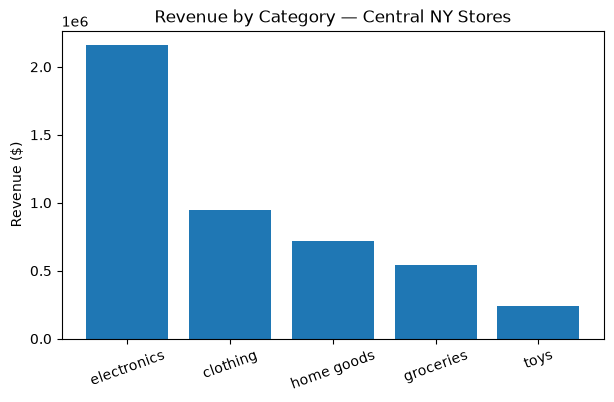

In [6]:
# Visualizing the result -- same pandas/matplotlib workflow from Classes 8-9
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(summary.index, summary.values)
ax.set_title("Revenue by Category — Central NY Stores")
ax.set_ylabel("Revenue ($)")
ax.tick_params(axis="x", rotation=20)
plt.show()


## 4. Writing a DataFrame Back into the Database

`.to_sql()` is the reverse direction of everything you've done so far — it takes a pandas DataFrame and saves it as a new table in the database, exactly how the `sales` and `stores` tables themselves were created in the first place.


In [7]:
# Save a summary table back into the database as a new table
revenue_by_region = (
    pd.read_sql_query(
        "SELECT st.region, SUM(s.revenue) AS total_revenue "
        "FROM sales AS s INNER JOIN stores AS st ON s.store = st.store "
        "GROUP BY st.region",
        conn
    )
)
revenue_by_region.to_sql("region_summary", conn, if_exists="replace", index=False)

# Confirm it's really there by querying it back
print(pd.read_sql_query("SELECT * FROM region_summary", conn))


             region  total_revenue
0  Capital District     1477075.47
1        Central NY     4602739.67


**`if_exists="replace"`** tells pandas what to do if a table with that name already exists — `"replace"` overwrites it, `"append"` adds new rows to it, and the default, `"fail"`, raises an error rather than risk overwriting something by accident.


In [8]:
# Confirm the database now has three tables
print(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn))


             name
0           sales
1          stores
2  region_summary


**Why this matters:** this is the full loop — a database can feed pandas, and pandas can feed back into the database. Real analytics pipelines often look exactly like this: pull data, transform/summarize it, store the result back for other tools or people to use.


In [9]:
conn.close()


---
# Part 2 — Midterm Review

The practical midterm (Class 15, Oct 26) is a hands-on exam: import, clean, query, summarize, visualize, and explain an unfamiliar dataset — in 60 minutes, with open notes/documentation but closed collaboration and closed AI tools.


## Topic Checklist

Use this to self-assess where you feel solid versus shaky. Go back to the specific class's notebook for anything that doesn't feel automatic yet.

**Python fundamentals (Classes 2–3)**
- Variables, types, type conversion
- Conditionals, loops, `break`/`continue`
- Functions, parameters, return values
- Lists and dictionaries

**pandas core (Classes 4–5)**
- Reading a CSV, `.head()`, `.shape`, `.dtypes`, `.info()`, `.describe()`
- Selecting columns, filtering rows (`&`, `|`, `.isin()`)
- Sorting, grouping, `.agg()`

**Data cleaning (Classes 6–7)**
- Detecting missing values (`.isna()`), `.dropna()` vs. `.fillna()`
- Finding and removing duplicates
- `.str` methods, regex, fixing inconsistent category text
- Converting to datetime, extracting date parts

**Visualization (Classes 8–9)**
- matplotlib: line, bar, histogram, scatter — and which chart fits which question
- seaborn: box plots, `hue`, automatic aggregation

**Programmatic data access (Classes 10–11)**
- Reading/writing CSV, JSON, Excel, Parquet
- Making a GET request, checking status codes, query parameters
- Safe credential handling (not on the midterm itself, but good practice)

**SQL (Classes 12–14)**
- `SELECT`, `WHERE`, `ORDER BY`, `GROUP BY`, `HAVING`
- `INNER JOIN` vs. `LEFT JOIN`
- Running a query from Python with `pd.read_sql_query()`


## Common Mistakes, Consolidated

A quick list pulled from every class so far — these account for the large majority of real mistakes seen in homework grading this semester.


- Using `=` instead of `==` in a comparison
- Using Python's `and`/`or` instead of pandas' `&`/`|`
- Forgetting `index=False` when writing to CSV/Excel
- Filling missing values with `0` without considering whether that's a reasonable stand-in for "unknown"
- Assuming `.dropna()`, `.sort_values()`, etc. modify a DataFrame in place — they return a new one unless reassigned
- Using single `[ ]` instead of double `[[ ]]` to select multiple columns
- Not checking `.unique()` on a text column before grouping by it
- Using `WHERE value = NULL` instead of `WHERE value IS NULL`
- **Reloading a raw CSV partway through a notebook, silently discarding earlier cleaning work** — this has been the single most common real error seen in HW grading this semester. Keep track of what `sales` currently contains at each point in your notebook.


## Integrated Practice

These exercises combine several skills end-to-end, similar in spirit to the midterm — using `retail_sales.csv` (the **raw**, uncleaned file) so you get one more rehearsal of the full pipeline before the real thing. Note: `retail_sales.db`'s `sales` table was built from the *cleaned* data back in Class 12 — keep that in mind for Practice 2. Solutions are provided below since this is review, not graded.


### Practice 1 — Full pipeline
Starting from a fresh `pd.read_csv("retail_sales.csv")`: report missing values, remove duplicates, fill missing `units_sold`/`revenue` with the median, and clean `category` into `category_clean` with exactly 5 values.


In [10]:
# Practice 1 — your code here
sales = pd.read_csv("retail_sales.csv")
print("Missing values:\n", sales.isna().sum())

sales = sales.drop_duplicates()

sales["units_sold"] = sales["units_sold"].fillna(sales["units_sold"].median())
sales["revenue"] = sales["revenue"].fillna(sales["revenue"].median())

sales["category_clean"] = sales["category"].str.lower().str.strip()
sales["category_clean"] = sales["category_clean"].str.replace(r"[_\s]+", " ", regex=True)
sales["category_clean"] = sales["category_clean"].replace({"cloth ing": "clothing"})

print("\nCleaned categories:", sorted(sales["category_clean"].unique()))


Missing values:
 date           0
store          0
category       0
units_sold    60
revenue       60
dtype: int64

Cleaned categories: ['clothing', 'electronics', 'groceries', 'home goods', 'toys']


### Practice 2 — Query and compare
Using your cleaned DataFrame from Practice 1, compute total revenue per store in pandas. Separately, connect to `retail_sales.db` and compute the same thing in SQL using its `sales` table. Compare the two results — what do you notice, and why does that make sense?


In [11]:
# Practice 2 — your code here
pandas_result = sales.groupby("store")["revenue"].sum().sort_values(ascending=False)
print("pandas (cleaned data):")
print(pandas_result)

conn = sqlite3.connect("retail_sales.db")
sql_result = pd.read_sql_query(
    """SELECT store, SUM(revenue) AS total_revenue FROM sales GROUP BY store ORDER BY total_revenue DESC""",
    conn
)
print("\nSQL (via retail_sales.db):")
print(sql_result)
conn.close()

# The numbers MATCH exactly. That's not a coincidence: retail_sales.db's "sales"
# table was built (back in Class 12) from retail_sales_clean.csv -- the same
# cleaned data you just reproduced by hand in Practice 1. This is actually a nice
# confirmation that both tools converge on the same answer when they start from
# the same clean data. (This will NOT always be true -- if a database table holds
# raw, uncleaned data, as some real systems do, you would need to query it with
# that in mind, or clean the result after pulling it into pandas.)


pandas (cleaned data):
store
Utica       1562319.71
Rome        1521763.90
Syracuse    1518656.06
Albany      1477075.47
Name: revenue, dtype: float64

SQL (via retail_sales.db):
      store  total_revenue
0     Utica     1562319.71
1      Rome     1521763.90
2  Syracuse     1518656.06
3    Albany     1477075.47


### Practice 3 — Visualize and explain
Create one chart showing average revenue per cleaned category. In 1–2 sentences, explain why this number would have been misleading if computed on the uncleaned `category` column.


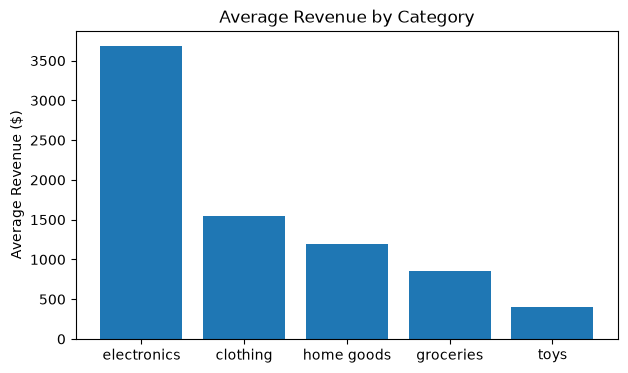

In [12]:
# Practice 3 — your code here
avg_by_category = sales.groupby("category_clean")["revenue"].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(avg_by_category.index, avg_by_category.values)
ax.set_title("Average Revenue by Category")
ax.set_ylabel("Average Revenue ($)")
plt.show()

# Using the uncleaned column would have split each real category across 2-3 text
# variants (e.g., "Electronics" vs "electronics" vs "ELECTRONICS"), so none of the
# per-category averages would reflect the true combined group.


---
## Solutions


In [13]:
# Solution — Practice 1
sales = pd.read_csv("retail_sales.csv")
print("Missing values:\n", sales.isna().sum())

sales = sales.drop_duplicates()

sales["units_sold"] = sales["units_sold"].fillna(sales["units_sold"].median())
sales["revenue"] = sales["revenue"].fillna(sales["revenue"].median())

sales["category_clean"] = sales["category"].str.lower().str.strip()
sales["category_clean"] = sales["category_clean"].str.replace(r"[_\s]+", " ", regex=True)
sales["category_clean"] = sales["category_clean"].replace({"cloth ing": "clothing"})

print("\nCleaned categories:", sorted(sales["category_clean"].unique()))


Missing values:
 date           0
store          0
category       0
units_sold    60
revenue       60
dtype: int64

Cleaned categories: ['clothing', 'electronics', 'groceries', 'home goods', 'toys']


In [14]:
# Solution — Practice 2
pandas_result = sales.groupby("store")["revenue"].sum().sort_values(ascending=False)
print("pandas (cleaned data):")
print(pandas_result)

conn = sqlite3.connect("retail_sales.db")
sql_result = pd.read_sql_query(
    """SELECT store, SUM(revenue) AS total_revenue FROM sales GROUP BY store ORDER BY total_revenue DESC""",
    conn
)
print("\nSQL (via retail_sales.db):")
print(sql_result)
conn.close()

# The numbers MATCH exactly. That's not a coincidence: retail_sales.db's "sales"
# table was built (back in Class 12) from retail_sales_clean.csv -- the same
# cleaned data you just reproduced by hand in Practice 1. This is actually a nice
# confirmation that both tools converge on the same answer when they start from
# the same clean data. (This will NOT always be true -- if a database table holds
# raw, uncleaned data, as some real systems do, you would need to query it with
# that in mind, or clean the result after pulling it into pandas.)


pandas (cleaned data):
store
Utica       1562319.71
Rome        1521763.90
Syracuse    1518656.06
Albany      1477075.47
Name: revenue, dtype: float64

SQL (via retail_sales.db):
      store  total_revenue
0     Utica     1562319.71
1      Rome     1521763.90
2  Syracuse     1518656.06
3    Albany     1477075.47


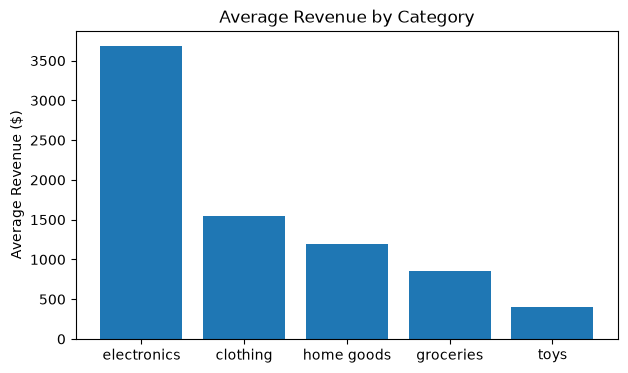

In [15]:
# Solution — Practice 3
avg_by_category = sales.groupby("category_clean")["revenue"].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(avg_by_category.index, avg_by_category.values)
ax.set_title("Average Revenue by Category")
ax.set_ylabel("Average Revenue ($)")
plt.show()

# Using the uncleaned column would have split each real category across 2-3 text
# variants (e.g., "Electronics" vs "electronics" vs "ELECTRONICS"), so none of the
# per-category averages would reflect the true combined group.


---
## Wrap-up

**Recap:** parameterized SQL queries (`?` placeholders, safer than string-formatting values in); chaining a SQL result into further pandas work; writing a DataFrame back into the database with `.to_sql()`; and a full review of Classes 1–13's material ahead of the midterm.

**HW4 is assigned today.**

**Midterm logistics reminder (Class 15, Oct 26):**
- In person, 60 minutes, your own laptop, already-configured environment
- Open notes/documentation, **closed collaboration, closed AI tools**
- Submission via Brightspace only
- A new, unfamiliar dataset will be provided — the skills, not the specific data, are what's being tested
